In [1]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
from collections import Counter
import math
import mplhep as hep
hep.style.use(hep.style.ROOT)

def sqrt(x,y):
        return (x/y)**0.5

def soft(x,y):
        return (x/y)/(1+x/y)

def ln(x,y):
        return math.log(1+x/y)

In [2]:
h5_file = "/eos/cms/store/group/phys_higgs/ttHbb/ntuples/ttHbb_export/training_fixedwp_dec25/training_no_toppt_var/fixed_wp/h5_files/ttbb_tthbb_non_semilep_tthbb_semilep_genmatched_train_3491469.h5"

In [3]:
f = h5py.File(h5_file, 'r')
f.keys()

<KeysViewHDF5 ['CLASSIFICATIONS', 'INPUTS', 'TARGETS', 'WEIGHTS']>

In [4]:
f['CLASSIFICATIONS']["EVENT"].keys()
signal  = f["CLASSIFICATIONS"]["EVENT"]['signal'][()]

In [5]:
f['INPUTS'].keys()

<KeysViewHDF5 ['Event', 'Jet', 'Lepton', 'Met']>

In [6]:
f['TARGETS'].keys()

<KeysViewHDF5 ['h', 't1', 't2']>

In [7]:
weights = f["WEIGHTS"]["weight"]

In [8]:
sum(weights[()]<0)

np.int64(52933)

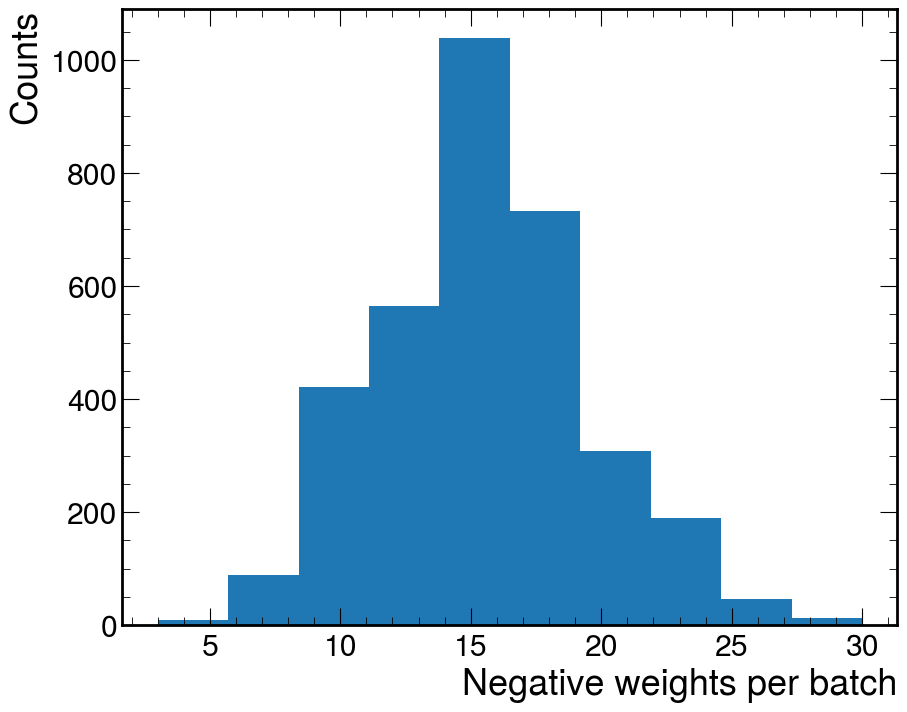

In [9]:
batch_size = 1024
num_batches = int(np.ceil(len(weights) / batch_size))

# Count negatives in each batch
negative_counts = []
for i in range(num_batches):
    batch = weights[i * batch_size : (i + 1) * batch_size]
    count_negatives = np.sum(batch < 0)
    negative_counts.append(count_negatives)

# Convert to a numpy array if you want
negative_counts = np.array(negative_counts)
plt.figure(figsize=(10,8))
plt.hist(negative_counts)
plt.xlabel("Negative weights per batch")
plt.ylabel("Counts")
#plt.title("Distribution of Negative Weights per Batch")
plt.show()

Text(1, 0, 'Weights')

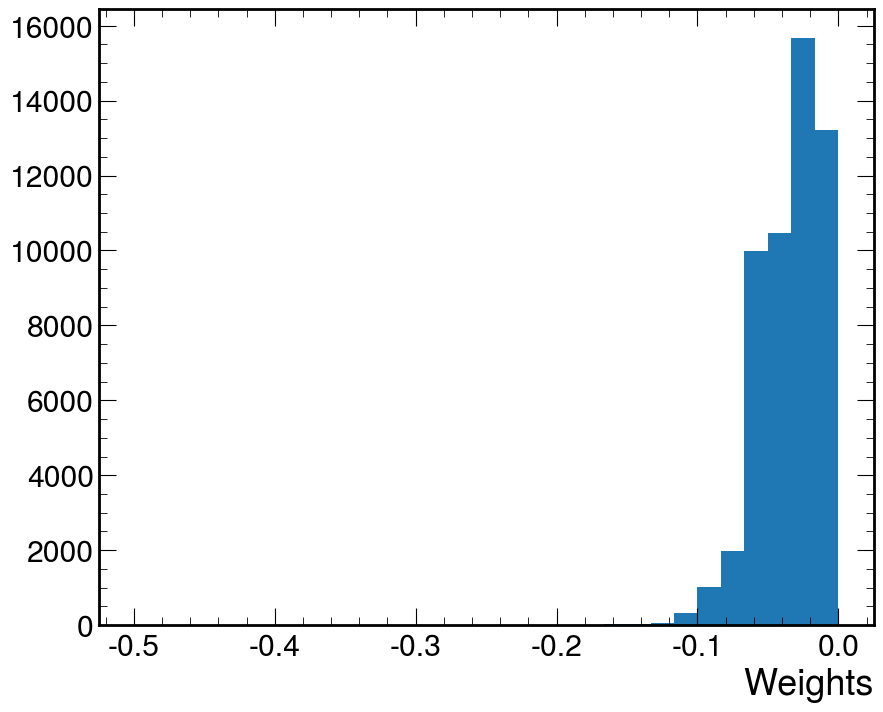

In [10]:
plt.figure(figsize=(10,8))
plt.hist(weights[()], range=(-0.5,0),bins=30)
plt.xlabel("Weights")

In [11]:
event_counts = dict()
class_index = signal[:]
classes = np.unique(class_index)
for i in range(len(classes)):
    event_counts[i+1] = weights[class_index == (i + 1)].sum()

In [12]:
classes

array([2, 3, 4, 5, 6])

In [13]:
#mapping_encoding:
#  signal:
#    TTH_Hto2B: 1
#    ttB: 2
#    ttC: 3
#    ttLF: 4
#    ttv: 5
#    singlet: 6
#    vjets: 7 -> excluded for now for too little counts
#    vv: 8 -> excluded for now for too little counts

In [14]:
event_counts

{1: np.float32(0.0),
 2: np.float32(50012.29),
 3: np.float32(18737.945),
 4: np.float32(67229.37),
 5: np.float32(575.6004)}

In [15]:
n_tot_events = sum(event_counts.values())
n_tot_sample = len(weights)

In [16]:
n_tot_events

np.float32(136555.19)

In [17]:
n_tot_sample

3491469

In [18]:
factor = dict()
rescaled_weights = dict()

for key in event_counts.keys():
    w = weights[class_index == key] 
    factor[key] = n_tot_sample/event_counts[key]
    rescaled_weights[key] =  w[~np.isnan(w)]* factor[key]

/tmp/ipykernel_584/1728172284.py:6: RuntimeWarning: divide by zero encountered in scalar divide
  factor[key] = n_tot_sample/event_counts[key]


In [19]:
factor

{1: np.float32(inf),
 2: np.float32(69.81222),
 3: np.float32(186.33148),
 4: np.float32(51.93369),
 5: np.float32(6065.786)}

In [20]:
rescaled_weights

{1: array([], dtype=float32),
 2: array([-1.5319595,  1.826686 ,  2.9037623, ...,  0.7650633,  1.4787464,
         1.6526461], dtype=float32),
 3: array([ 0.4174806,  5.927051 , 15.263783 , ...,  5.1274304,  3.8125792,
         6.531154 ], dtype=float32),
 4: array([6.5706587 , 0.52771574, 3.26056   , ..., 1.159799  , 3.296935  ,
        1.0060134 ], dtype=float32),
 5: array([ 128.11884, -128.16808,  254.30423, ..., -130.49153,  109.80398,
         153.03546], dtype=float32)}

In [21]:
for key, values in rescaled_weights.items():
    print(f'{key}: mean = {np.mean(values)}, std = {np.std(values)}')

1: mean = nan, std = nan
2: mean = 2.535280466079712, std = 1.7180179357528687
3: mean = 7.561465263366699, std = 4.847203731536865
4: mean = 2.3398196697235107, std = 1.5442181825637817
5: mean = 62.37215805053711, std = 192.4551239013672


/cvmfs/sft.cern.ch/lcg/views/LCG_108_swan/x86_64-el9-gcc13-opt/lib/python3.12/site-packages/numpy/_core/fromnumeric.py:3904: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/cvmfs/sft.cern.ch/lcg/views/LCG_108_swan/x86_64-el9-gcc13-opt/lib/python3.12/site-packages/numpy/_core/_methods.py:147: RuntimeWarning: invalid value encountered in divide
  ret = ret.dtype.type(ret / rcount)
/cvmfs/sft.cern.ch/lcg/views/LCG_108_swan/x86_64-el9-gcc13-opt/lib/python3.12/site-packages/numpy/_core/_methods.py:227: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/cvmfs/sft.cern.ch/lcg/views/LCG_108_swan/x86_64-el9-gcc13-opt/lib/python3.12/site-packages/numpy/_core/_methods.py:184: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/cvmfs/sft.cern.ch/lcg/views/LCG_108_swan/x86_64-el9-gcc13-opt/lib/python3.12/site-packages/numpy/_core/_methods.py:219